In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

print("Libraries imported successfully: pandas, matplotlib, seaborn, sklearn")

Libraries imported successfully: pandas, matplotlib, seaborn, sklearn


In [2]:
iris = load_iris()
X = iris.data
y = iris.target

print("X shape (features):", X.shape)
print("y shape (target):  ", y.shape)
print("Feature names:", iris.feature_names)
print("Target class names:", iris.target_names)

X shape (features): (150, 4)
y shape (target):   (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target class names: ['setosa' 'versicolor' 'virginica']


In [3]:
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target
df.head()
# df.tail()
# df.sample(10)
df.tail()
df.sample(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
28,5.2,3.4,1.4,0.2,0
39,5.1,3.4,1.5,0.2,0
79,5.7,2.6,3.5,1.0,1
65,6.7,3.1,4.4,1.4,1
24,4.8,3.4,1.9,0.2,0
63,6.1,2.9,4.7,1.4,1
9,4.9,3.1,1.5,0.1,0
146,6.3,2.5,5.0,1.9,2
103,6.3,2.9,5.6,1.8,2
44,5.1,3.8,1.9,0.4,0


In [5]:
df.to_csv("iris.csv", index=False)   # WRITE the DataFrame to disk
df = pd.read_csv("iris.csv")          # READ it back into a fresh DataFrame

print("Reloaded DataFrame shape:", df.shape)
df.shape

Reloaded DataFrame shape: (150, 5)


(150, 5)

In [6]:

# df.columns — WHY: confirms exact column names/spelling before referencing them.
df.columns.tolist()

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)',
 'target']

In [11]:
# df.describe() — WHY: summary statistics reveal scale and spread before modeling.
df.describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [ ]:
# Missing values — df.isnull() marks every cell True/False; .sum() counts per column.
df.isnull().sum()


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

In [15]:
# Duplicate rows — df.duplicated() flags exact-repeat rows; .sum() counts them.
df.duplicated().sum()

np.int64(1)

In [16]:
# Unique values per column
df.nunique()

sepal length (cm)    35
sepal width (cm)     23
petal length (cm)    43
petal width (cm)     22
target                3
dtype: int64

In [17]:
# Target / class distribution — checking BALANCE before ever training a model.
df["target"].value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

In [18]:
df.iloc[0].unique()

array([5.1, 3.5, 1.4, 0.2, 0. ])

In [3]:
import os
PLOTS_DIR = "plots"
os.makedirs(PLOTS_DIR, exist_ok=True)

In [2]:
plt.figure(figsize=(7, 5))
plt.hist(df["sepal length (cm)"], bins=15, color="#4C72B0", edgecolor="white")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Frequency")
plt.title("Distribution of Sepal Length")
plt.tight_layout()
plt.legend(["Sepal Length"])

plt.savefig(os.path.join(PLOTS_DIR, "01_histogram_sepal_length.png"), dpi=150)
plt.show()

NameError: name 'df' is not defined

<Figure size 700x500 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.figure(figsize=(7, 5))

sns.boxplot(
    x="species",
    y="petal width (cm)",
    data=df
)

plt.xlabel("Species")
plt.ylabel("Petal Width")
plt.title("Petal Width by Species")

plt.tight_layout()

plt.savefig(
    os.path.join(PLOTS_DIR, "02_boxplot_petal_width.png"),
    dpi=150
)

plt.show()

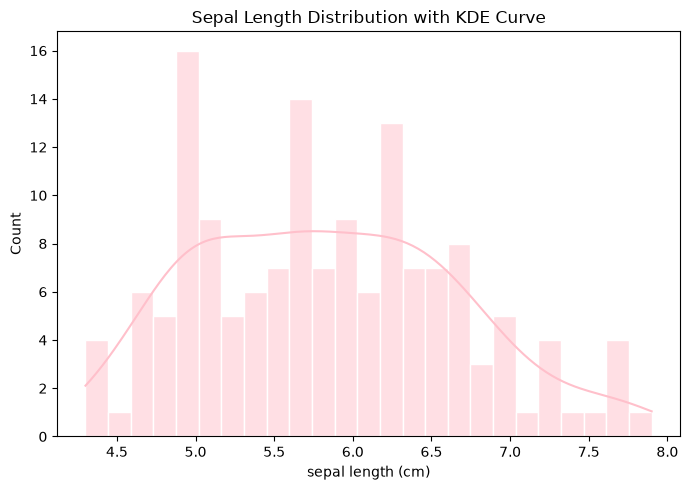

In [23]:
plt.figure(figsize=(7, 5))
sns.histplot(data=df, x="sepal length (cm)", kde=True, color="pink", edgecolor="white", bins=25)
plt.title("Sepal Length Distribution with KDE Curve")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "02_histplot_kde_sepal_length.png"), dpi=150)
plt.show()

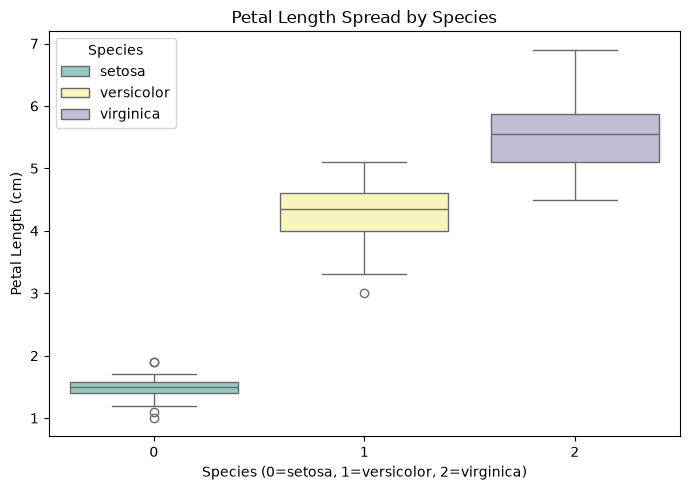

In [24]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="target", y="petal length (cm)", hue="target",
            palette="Set3", legend=True)
plt.xlabel("Species (0=setosa, 1=versicolor, 2=virginica)")
plt.ylabel("Petal Length (cm)")
plt.title("Petal Length Spread by Species")
plt.tight_layout()
plt.legend(title="Species", loc="upper left", labels=iris.target_names)
plt.savefig(os.path.join(PLOTS_DIR, "03_boxplot_petal_length.png"), dpi=150)
plt.show()

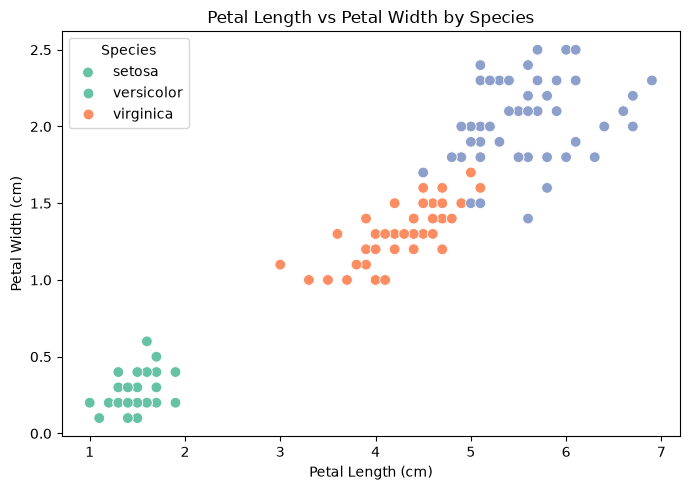

In [25]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="petal length (cm)", y="petal width (cm)",
                 hue="target", palette="Set2", s=60)
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Petal Length vs Petal Width by Species")
plt.tight_layout()
plt.legend(title="Species", loc="upper left", labels=iris.target_names)
plt.savefig(os.path.join(PLOTS_DIR, "04_scatterplot_petal.png"), dpi=150)
plt.show()

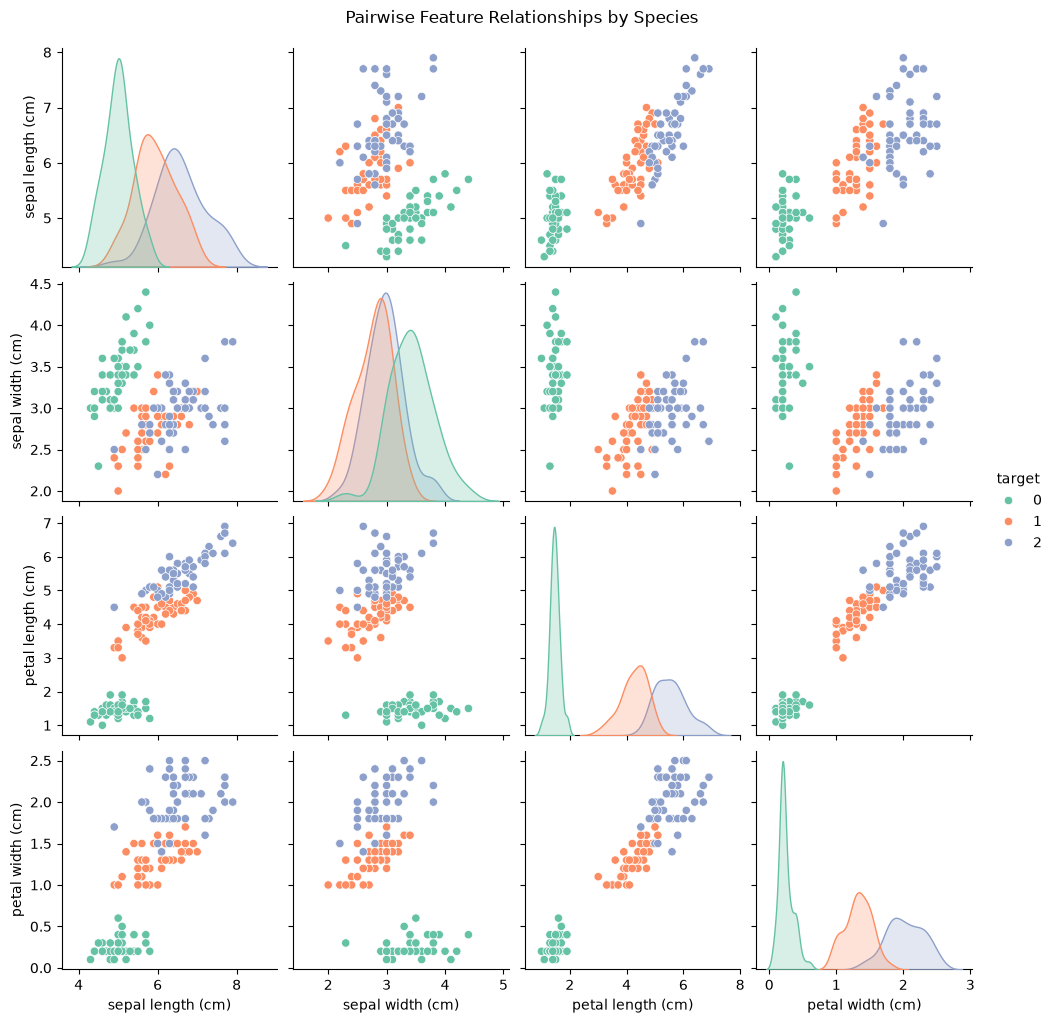

In [26]:
pairplot_fig = sns.pairplot(df, hue="target", palette="Set2", corner=False)
pairplot_fig.figure.suptitle("Pairwise Feature Relationships by Species", y=1.02)
pairplot_fig.savefig(os.path.join(PLOTS_DIR, "05_pairplot_iris.png"), dpi=150)
plt.show()

In [27]:
correlation = df.drop("target", axis=1).corr()
correlation

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


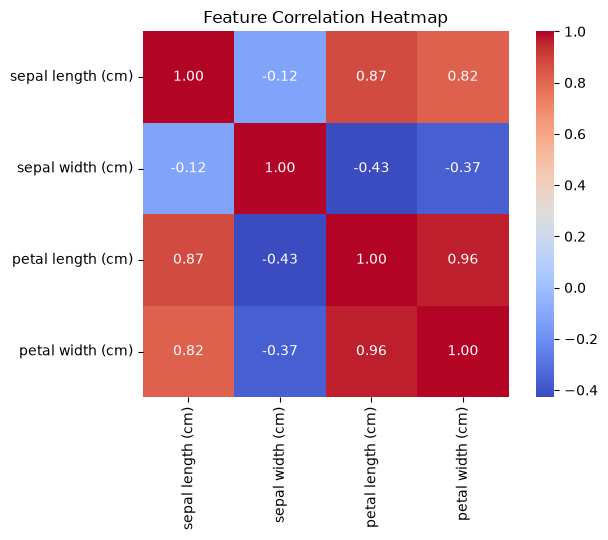

In [28]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "06_heatmap_correlation.png"), dpi=150)
plt.show()

In [3]:
import seaborn as sns
import pandas as pd

df = sns.load_dataset("iris")

print(df.head())
print(df.columns)

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')


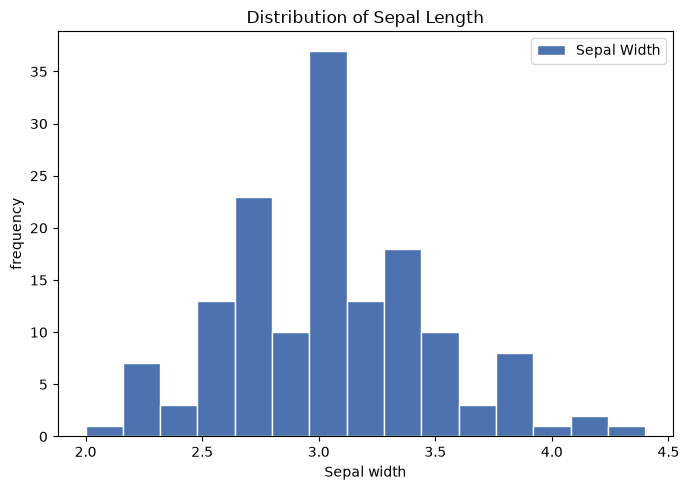

In [7]:
#mini challenge
import matplotlib.pyplot  as plt
plt.figure(figsize=(7, 5))
plt.hist(df["sepal_width"],bins=15, color="#4C72B0", edgecolor="white")
plt.xlabel("Sepal width")
plt.ylabel("frequency")
plt.title("Distribution of Sepal Length")
plt.tight_layout()
plt.legend(["Sepal Width"])

plt.show()


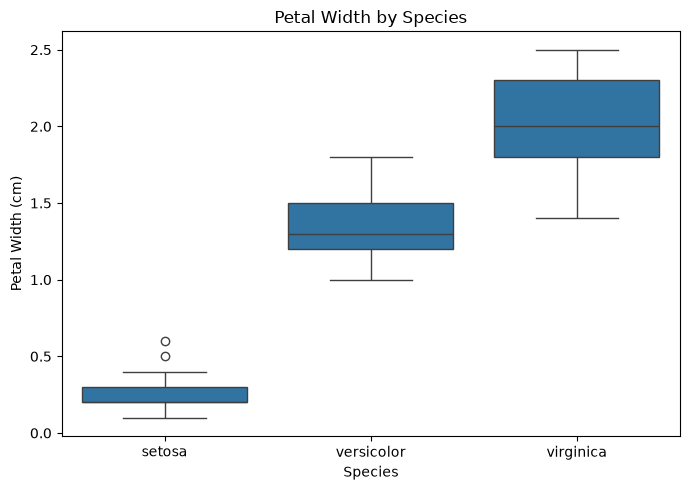

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.figure(figsize=(7, 5))

sns.boxplot(
    x="species",
    y="petal_width",
    data=df
)

plt.xlabel("Species")
plt.ylabel("Petal Width (cm)")
plt.title("Petal Width by Species")

plt.tight_layout()



plt.show()

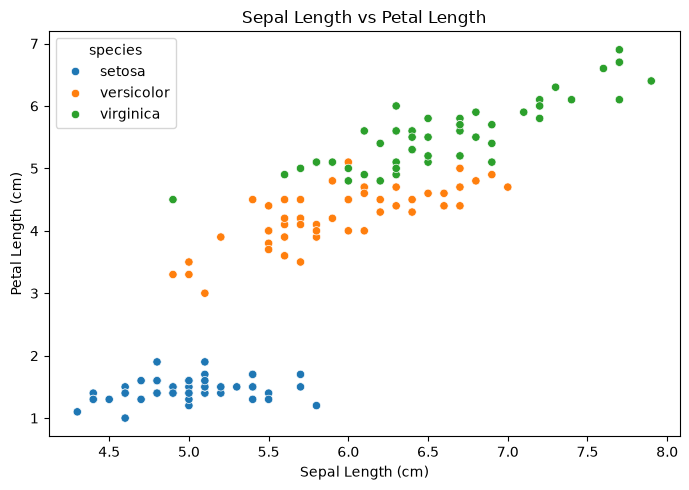

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.scatterplot(
    x="sepal_length",
    y="petal_length",
    hue="species",
    data=df
)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Sepal Length vs Petal Length")

plt.tight_layout()

plt.show()

In [14]:
print(df.columns)


Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')


In [20]:
# TODO: filter for attendance < 70, then compute the mean marks

import pandas as pd
import numpy as np

data2 = {
    "employee_id": [1, 2, 3, 4, 5, 6],
    "department": ["Eng", "Sales", "Eng", "Sales", "Eng", "Sales"],
    "experience_years": [1, 5, 3, 8, 2, 6],
    "salary": [30000, 65000, 48000, 90000, 35000, 72000],
}

employee_df = pd.DataFrame(data2)

print(employee_df.columns)

# 1. Data inspection
employee_df.info()
print(employee_df.describe())

# 2. Groupby
print("\nMean salary by department:")
print(employee_df.groupby("department")["salary"].mean())

# 3. Filter
print("\nEmployees with experience >= 3:")
print(employee_df[employee_df["experience_years"] >= 3])

# 4. NumPy calculation
salary_array = np.array(employee_df["salary"])
print("\nSalary standard deviation:")
print(salary_array.std())

# 5. Function
def bonus(salary):
    return salary * 0.10

employee_df["bonus"] = employee_df["salary"].apply(bonus)

print("\nFinal DataFrame:")
print(employee_df)

Index(['employee_id', 'department', 'experience_years', 'salary'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   employee_id       6 non-null      int64
 1   department        6 non-null      str  
 2   experience_years  6 non-null      int64
 3   salary            6 non-null      int64
dtypes: int64(3), str(1)
memory usage: 324.0 bytes
       employee_id  experience_years        salary
count     6.000000          6.000000      6.000000
mean      3.500000          4.166667  56666.666667
std       1.870829          2.639444  23114.209194
min       1.000000          1.000000  30000.000000
25%       2.250000          2.250000  38250.000000
50%       3.500000          4.000000  56500.000000
75%       4.750000          5.750000  70250.000000
max       6.000000          8.000000  90000.000000

Mean salary by department:
department
Eng      376

In [16]:
#hw: todos


def letter_grade(marks):
    if marks >= 90:
        return "A"
    elif marks >= 80:
        return "B"
    elif marks >= 70:
        return "C"
    elif marks >= 60:
        return "D"
    else:
        return "F"

print(letter_grade(95))
print(letter_grade(80))
print(letter_grade(50))
print(letter_grade(20))

A
B
F
F


In [ ]:
import numpy as np
scores = np.array([65, 40, 90, 30, 85])

# TODO (a) mean
# TODO (b) boolean mask: scores >= 40
# TODO (c) count of passed using mask.sum()
# TODO (d) descending sort: hint - np.sort(scores)[::-1]

import numpy as np

scores = np.array([65, 40, 90, 30, 85])

mean_score = np.mean(scores)

mask = scores >= 40

passed_count = mask.sum()

descending_scores = np.sort(scores)[::-1]

print("Mean:", mean_score)
print("Mask:", mask)
print("Passed count:", passed_count)
print("Descending:", descending_scores)

Mean: 62.0
Mask: [ True  True  True False  True]
Passed count: 4
Descending: [90 85 65 40 30]


In [ ]:
### Level 3 — Integrated Challenge
import pandas as pd
import numpy as np

data2 = {
    "employee_id": [1, 2, 3, 4, 5, 6],
    "department": ["Eng", "Sales", "Eng", "Sales", "Eng", "Sales"],
    "experience_years": [1, 5, 3, 8, 2, 6],
    "salary": [30000, 65000, 48000, 90000, 35000, 72000],
}

df = pd.DataFrame(data2)

print("DataFrame:")
print(df)

print("\n--- Info ---")
df.info()

print("\n--- Describe ---")
print(df.describe())

mean_salary = df.groupby("department")["salary"].mean()

print("\nMean salary by department:")
print(mean_salary)
experienced = df[df["experience_years"] >= 3]

print("\nEmployees with experience >= 3 years:")
print(experienced)

salary_array = df["salary"].to_numpy()

salary_std = salary_array.std()

print("\nSalary standard deviation:")
print(salary_std)

def bonus(salary):
    return salary * 0.10

df["bonus"] = df["salary"].apply(bonus)

print("\nDataFrame with bonus:")
print(df)

DataFrame:
   employee_id department  experience_years  salary
0            1        Eng                 1   30000
1            2      Sales                 5   65000
2            3        Eng                 3   48000
3            4      Sales                 8   90000
4            5        Eng                 2   35000
5            6      Sales                 6   72000

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   employee_id       6 non-null      int64
 1   department        6 non-null      str  
 2   experience_years  6 non-null      int64
 3   salary            6 non-null      int64
dtypes: int64(3), str(1)
memory usage: 324.0 bytes

--- Describe ---
       employee_id  experience_years        salary
count     6.000000          6.000000      6.000000
mean      3.500000          4.166667  56666.666667
std       1.870829          2.

In [29]:
summary = f"""
1. Observations            : {df.shape[0]} rows
2. Features                 : {df.shape[1] - 1} numeric columns
                               (sepal length, sepal width, petal length, petal width)
3. Target                   : 'species' (0=setosa, 1=versicolor, 2=virginica)
4. Missing values           : {df.isnull().sum().sum()} (none)
5. Duplicate rows           : {df.duplicated().sum()}
6. Class balance            : {dict(df['target'].value_counts())} (perfectly balanced: 50/50/50)
7. Strongly related features: petal length <-> petal width (correlation ~0.96)
8. Most useful features for classification: petal length & petal width
   (cleanest visual separation between species)
9. Distribution shape       : roughly bell-shaped for most features, with
                               setosa forming a visibly separate cluster
10. Potential outliers       : a small few visible in boxplots, none extreme
11. Suitability for ML       : YES - clean, balanced, well-separated data is
                               IDEAL for a first classification project
"""
print(summary)
print("WORKFLOW RECAP:")
print("Raw Data -> Understanding -> EDA -> Visualization -> Insights -> ML")


1. Observations            : 150 rows
2. Features                 : 4 numeric columns
                               (sepal length, sepal width, petal length, petal width)
3. Target                   : 'species' (0=setosa, 1=versicolor, 2=virginica)
4. Missing values           : 0 (none)
5. Duplicate rows           : 1
6. Class balance            : {0: np.int64(50), 1: np.int64(50), 2: np.int64(50)} (perfectly balanced: 50/50/50)
7. Strongly related features: petal length <-> petal width (correlation ~0.96)
8. Most useful features for classification: petal length & petal width
   (cleanest visual separation between species)
9. Distribution shape       : roughly bell-shaped for most features, with
                               setosa forming a visibly separate cluster
10. Potential outliers       : a small few visible in boxplots, none extreme
11. Suitability for ML       : YES - clean, balanced, well-separated data is
                               IDEAL for a first classification pr